# FWI · Acoustic · Marmousi · **SEM backend**

The same end-to-end FWI workflow as *FWI · Acoustic · Marmousi*, but solved with
the **spectral-element method** instead of finite differences. The SEM solver is
driven through `sweep.sem.PropSEM`, which reproduces the FD `PropTorch` calling
convention — `prop(wavelet, sources, receivers, models=[vp_grid])` — so the
acquisition, optimizer and plotting code are unchanged.

Like the FD backend, the SEM solver has **two interchangeable implementations**
selected by `impl`: `'eager'` (pure PyTorch time step, autograd tape) and `'c'`
(custom CUDA kernels for the forward *and* the adjoint, wrapped in a
`torch.autograd.Function` — same equation, gradients match eager to fp32).

SEM-specific points (flagged inline):

* the `(nz, nx)` velocity **grid** is differentiably interpolated onto the
  spectral-element GLL nodes, so `loss.backward()` still returns the gradient on
  the original grid — directly comparable to the FD gradient;
* SEM injects the source as a body term into the mass-normalized acceleration, so
  a unit wavelet yields data far from O(1) — we rescale the wavelet once so the
  data sits at O(1) (the wave equation is linear in the source, so this is exact);
* the equation is `AcousticPotentialSEM2D` — SPECFEM's potential-form acoustic —
  because that is the one acoustic equation **both** impls implement (with constant
  density it is physically equivalent to the constant-density `AcousticSEM2D`).

## 1. Parameters  (identical to the FD Marmousi FWI notebook)

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.signal import ricker
from sweep.datasets import load_marmousi, MARMOUSI_DH
from sweep.propagator import BoundarySaving
from sweep.sem import PropSEM
from sweep.sem.equations.acoustic_potential2d import AcousticPotentialSEM2D
from sweep.sem.prop_c import sem_c_available

dh    = MARMOUSI_DH * 2   # 25 m (12.5 m -> 25 m via ::2,::2 downsample)
dt    = 0.002
nt    = 2000              # 4.0 s
freq  = 5.0
delay = 0.20
nshots, nrec, batch_shots = 20, 200, 8     # batch_shots=8 (matches FD nb01)
src_z, rec_z = 2, 4

lr, n_iter = 25.0, 30
n_order    = 4            # GLL polynomial degree (per element)
abcn       = 10 * n_order # CPML width in grid cells: ten elements

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# impl='c' runs the SEM forward + adjoint in custom CUDA kernels (same equation,
# same gradient — cos = 1.0 vs eager). Falls back to the eager PyTorch step on
# CPU or when sweep._C was built without CUDA.
impl = 'c' if (device.type == 'cuda' and sem_c_available()) else 'eager'
print('device:', device, '  impl:', impl)

device: cuda   impl: c


## 2. Load Marmousi and downsample to 25 m

shape: (141, 681)    physical extent: 3.5 km depth × 17.0 km offset


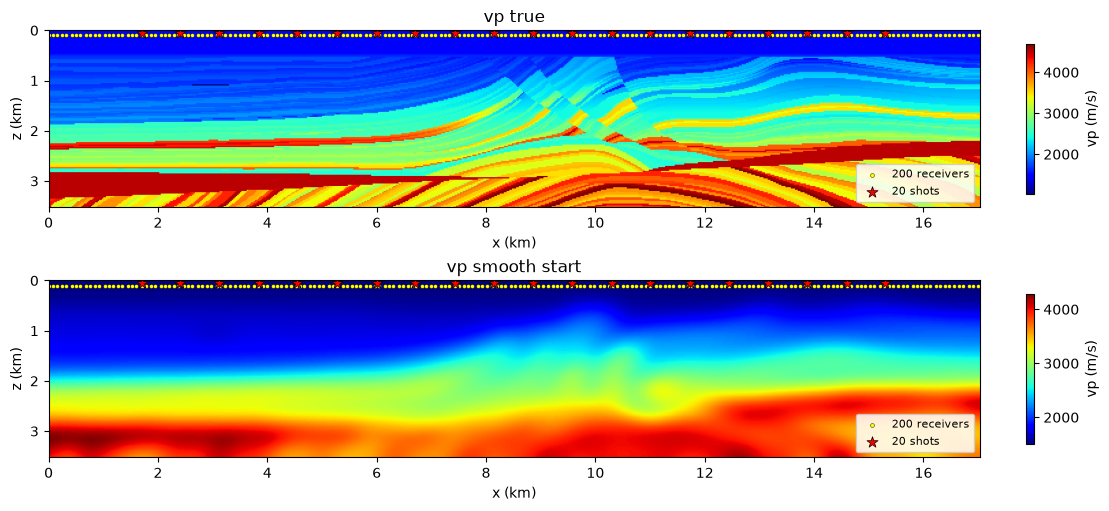

In [2]:
vp_true_np = load_marmousi('true')[::2, ::2].copy()
vp_init_np = load_marmousi('smooth')[::2, ::2].copy()
shape      = vp_true_np.shape
print('shape:', shape, '   physical extent:',
      f'{shape[0]*dh/1000:.1f} km depth × {shape[1]*dh/1000:.1f} km offset')

# Acquisition geometry: surface sources + horizontal receiver line
src_x = np.linspace(shape[1] * 0.1, shape[1] * 0.9, nshots).astype(np.int64)
rec_x = np.linspace(0, shape[1] - 1, nrec).astype(np.int64)
src_x_km = src_x * dh / 1000;  src_z_km = src_z * dh / 1000
rec_x_km = rec_x * dh / 1000;  rec_z_km = rec_z * dh / 1000

fig, axes = plt.subplots(2, 1, figsize=(11, 5), constrained_layout=True)
for ax, m, title in zip(axes, [vp_true_np, vp_init_np], ['true', 'smooth start']):
    im = ax.imshow(m, cmap='jet', aspect='auto',
                   extent=[0, shape[1]*dh/1000, shape[0]*dh/1000, 0])
    ax.scatter(rec_x_km, np.full_like(rec_x_km, rec_z_km, dtype=float),
               s=8, c='yellow', edgecolors='k', linewidths=0.3, label=f'{nrec} receivers')
    ax.scatter(src_x_km, np.full_like(src_x_km, src_z_km, dtype=float),
               s=70, c='red', marker='*', edgecolors='k', linewidths=0.5, label=f'{nshots} shots')
    ax.set_title(f'vp {title}')
    ax.set_xlabel('x (km)'); ax.set_ylabel('z (km)')
    ax.legend(loc='lower right', fontsize=8, framealpha=0.85)
    fig.colorbar(im, ax=ax, label='vp (m/s)', shrink=0.85)
plt.show()

## 3. Geometry, wavelet, SEM solver

`PropSEM` builds the GLL mesh + CPML internally from `shape`, `dh`, `n_order`
and `abcn` (Quad9 elements for `AcousticPotentialSEM2D`).
Sources/receivers are **integer grid indices** `[ix, iz]` exactly as in the FD
backend (converted to physical metres internally). As the FD `abcn` does, the
`abcn`-cell CPML layer -- whole elements, so a multiple of `n_order` -- is added
**outside** the given `shape`, on all four sides here: to match the FD notebook
there is no free surface (`free_surface=False`, the default). So `shape` is the
model and the integer source/receiver indices are model coordinates (the
surface sources are never inside the PML).

In [3]:
t = np.arange(nt, dtype=np.float32) * dt
wavelet0 = ricker(t - delay, f=freq).astype(np.float32)

sources   = np.stack([src_x, np.full(nshots, src_z, dtype=np.int64)], axis=1)
receivers = np.stack([rec_x, np.full(nrec, rec_z, dtype=np.int64)], axis=1)
receivers = np.repeat(receivers[None, ...], nshots, axis=0)

# AcousticPotentialSEM2D is SPECFEM's potential-form acoustic ((1/κ)χ̈ = ∇·(ρ⁻¹∇χ),
# κ = ρc²) — the ONE acoustic equation both impl='eager' and impl='c' implement.
# With the constant ``density`` it is physically equivalent to the constant-density
# AcousticSEM2D this notebook used before, and it also supports variable density.
# impl='c' keeps each shot's whole history (its custom adjoint); eager rebuilds it
# from the boundary instead, so one shot's autograd memory stays ~flat in nt.
solver = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt, nt=nt,
                 n_order=n_order, abcn=abcn, f_dominant=freq,
                 memory=None if impl == 'c' else BoundarySaving(),
                 device=device.type, impl=impl)
print('SEM mesh:', solver.mesh.n_elements, 'elements,',
      solver.mesh.n_global, 'GLL nodes  (grid had', shape[0]*shape[1], 'points)')

SEM mesh: 10450 elements, 168181 GLL nodes  (grid had 96021 points)


### Aside · source amplitude calibration

A unit Ricker drives the SEM body source to amplitudes far from O(1) (how far
depends on the equation's normalization — the potential χ is not a displacement).
Because the wave equation is **linear in the source**, we run one forward with the
unit wavelet, then rescale the wavelet (and the observed data) so the data sits at
O(1) — putting the MSE loss and gradient in the same numeric range the FD
notebook's `Adam(lr=25, eps=1e-16)` expects.

In [4]:
vp_true = torch.tensor(vp_true_np, device=device)

with torch.no_grad():
    obs0 = solver(wavelet0, sources, receivers, models=[vp_true])  # (nshots, nt, nrec, ncomp)
src_scale = 1.0 / float(obs0.pow(2).mean().sqrt())
wavelet   = wavelet0 * src_scale               # O(1) data
observed  = (obs0 * src_scale).detach()        # linear in source amplitude
print(f'source scale = {src_scale:.3e}   ->   observed RMS = '
      f'{float(observed.pow(2).mean().sqrt()):.3f}')
print('observed shape:', tuple(observed.shape))

source scale = 1.962e-01   ->   observed RMS = 1.000
observed shape: (20, 2000, 200, 1)


## 4. Observed gather (centre shot)

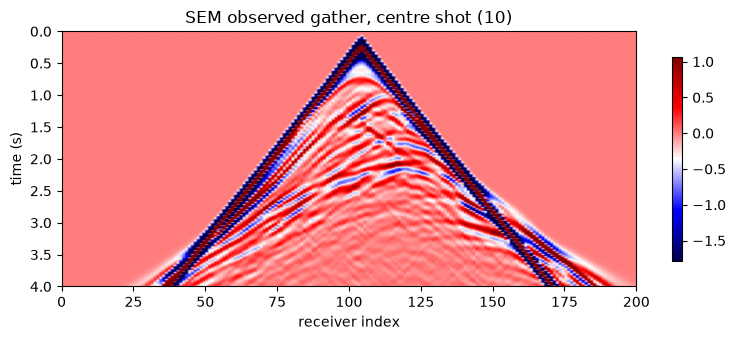

In [5]:
# PropSEM returns the FD layout (nshots, nt, nrec, ncomp); acoustic has
# ncomp = 1, so take that component to get a (nt, nrec) gather.
gather0 = observed[nshots // 2, :, :, 0].detach().cpu().numpy()
vmin, vmax = np.percentile(gather0, [2, 98])
plt.figure(figsize=(8, 3.5))
plt.imshow(gather0, cmap='seismic', vmin=vmin, vmax=vmax, aspect='auto',
           extent=[0, nrec, nt * dt, 0])
plt.xlabel('receiver index'); plt.ylabel('time (s)')
plt.title(f'SEM observed gather, centre shot ({nshots // 2})')
plt.colorbar(shrink=0.8); plt.tight_layout(); plt.show()

## 5. Stochastic Adam loop (mini-batch shots)

Each iteration draws a random batch of `batch_shots` shots and accumulates the
gradient **one shot at a time** — mathematically identical to the batched call,
but peak memory stays at *one* shot regardless of batch size. That matters for
`impl='c'`: its adjoint saves the full forward history (~6.7 GB/shot here), so a
batched call would hold `batch_shots × 6.7 GB` at once. For `impl='eager'` the
solver compiles its step (torch.compile, the default — ~2.4× faster; the first
iteration pays a one-time compile cost) and was built with
`memory=BoundarySaving()` (reverse-time reconstruction) — `impl='c'` needs
neither. Same loss
(mean-squared residual) and same `Adam(lr=25, eps=1e-16)` as the FD notebook.

In [6]:
import time
rng = np.random.default_rng(0)
t_start = time.time()
vp = torch.tensor(vp_init_np, device=device, requires_grad=True)
optimizer = torch.optim.Adam([vp], lr=lr, eps=1e-16)
losses = []

# eager compiles its step (and rebuilds the forward from the boundary, set on the
# solver); impl='c' has a custom CUDA adjoint. Shots are accumulated ONE AT A TIME
# so at most one shot's saved wavefield history is alive (impl='c' is save-all,
# ~6.7 GB per shot here); the summed per-shot gradient is identical to the batched one.

for it in range(n_iter):
    iter_t0 = time.time()
    idx = rng.choice(nshots, size=batch_shots, replace=False)
    optimizer.zero_grad()
    loss_val = 0.0
    for s in idx:                                   # one shot at a time
        predicted = solver(wavelet, sources[s:s+1], receivers[s:s+1],
                           models=[vp])
        loss = (predicted - observed[s:s+1]).pow(2).mean() / batch_shots
        loss.backward()                             # frees this shot's history now
        loss_val += float(loss.detach().cpu())
        del predicted, loss
    optimizer.step()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    losses.append(loss_val)
    print(f'iter {it:02d}  loss {losses[-1]:.4e}  '
          f'iter={time.time()-iter_t0:.2f}s  total={time.time()-t_start:.1f}s')

iter 00  loss 4.3401e-01  iter=4.07s  total=4.1s


iter 01  loss 2.6219e-01  iter=4.04s  total=8.1s


iter 02  loss 3.1688e-01  iter=4.06s  total=12.2s


iter 03  loss 2.1592e-01  iter=4.04s  total=16.2s


iter 04  loss 1.1380e-01  iter=4.00s  total=20.2s


...

iter 25  loss 4.8269e-02  iter=4.06s  total=105.2s


iter 26  loss 4.2101e-02  iter=4.05s  total=109.2s


iter 27  loss 3.8407e-02  iter=4.06s  total=113.3s


iter 28  loss 3.0918e-02  iter=4.00s  total=117.3s


iter 29  loss 2.6977e-02  iter=4.06s  total=121.4s


## 6. Results

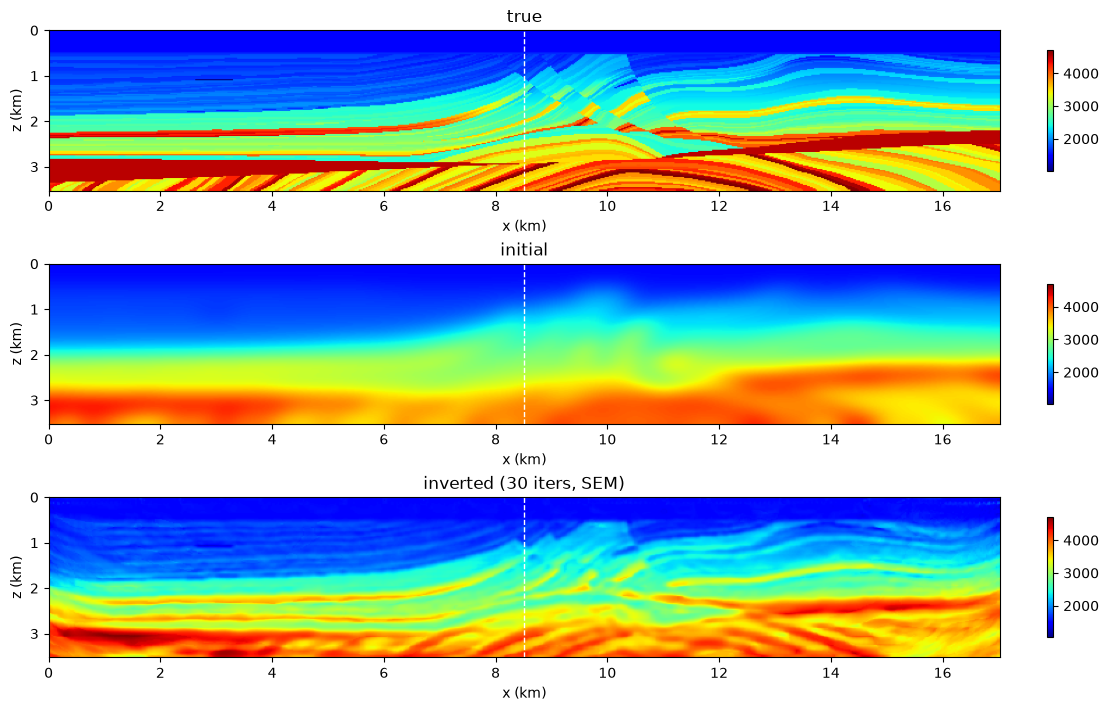

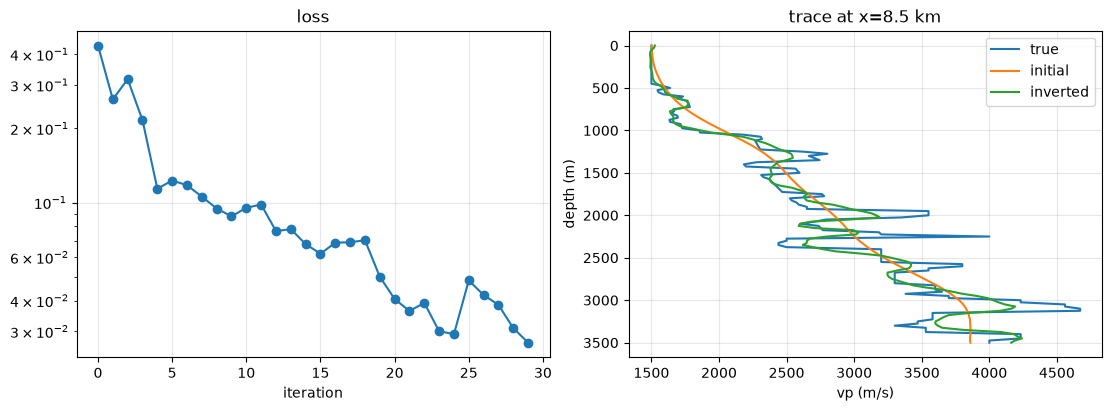

In [7]:
vp_final = vp.detach().cpu().numpy()
vmin_m = float(min(vp_true_np.min(), vp_init_np.min(), vp_final.min()))
vmax_m = float(max(vp_true_np.max(), vp_init_np.max(), vp_final.max()))
x_trace = shape[1] // 2
z_axis = np.arange(shape[0]) * dh

fig, axes = plt.subplots(3, 1, figsize=(11, 7), constrained_layout=True)
for ax, m, title in zip(
    axes, [vp_true_np, vp_init_np, vp_final],
    ['true', 'initial', f'inverted ({n_iter} iters, SEM)'],
):
    im = ax.imshow(m, cmap='jet', vmin=vmin_m, vmax=vmax_m, aspect='auto',
                   extent=[0, shape[1]*dh/1000, shape[0]*dh/1000, 0])
    ax.axvline(x_trace * dh / 1000, color='w', linewidth=1.0, linestyle='--')
    ax.set_title(title); ax.set_xlabel('x (km)'); ax.set_ylabel('z (km)')
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(losses, marker='o')
axes[0].set_title('loss'); axes[0].set_xlabel('iteration')
axes[0].set_yscale('log'); axes[0].grid(True, alpha=0.3)
axes[1].plot(vp_true_np[:, x_trace], z_axis, label='true')
axes[1].plot(vp_init_np[:, x_trace], z_axis, label='initial')
axes[1].plot(vp_final[:, x_trace],   z_axis, label='inverted')
axes[1].invert_yaxis()
axes[1].set_xlabel('vp (m/s)'); axes[1].set_ylabel('depth (m)')
axes[1].set_title(f'trace at x={x_trace * dh / 1000:.1f} km')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.show()

## Notes — SEM vs the FD notebook

* **Same API**: `PropSEM(eq, shape=..., dh=..., dt=..., abcn=..., ...)` +
  `prop(wavelet, sources, receivers, models=[vp_grid])` mirror the FD `PropTorch`,
  options included; only the imports and the source-amplitude rescaling differ.
* **Grid ↔ GLL**: the `(nz, nx)` model is bilinearly + differentiably interpolated
  onto the GLL nodes; the returned gradient is on the `(nz, nx)` grid.
* **`impl='c'` vs `'eager'`**: identical equation (`AcousticPotentialSEM2D`),
  forward + `dL/dvp` match to fp32 (`test/sem/test_propsem_c.py`). The CUDA
  backend runs an adjoint-state backward (save-all) instead of the autograd tape;
  per-shot gradient accumulation keeps its memory at one shot. `impl='c'`
  currently covers 2-D potential-form acoustic (bare + CPML) and 2-D elastic
  (bare); everything else falls back to eager (or raises, if forced).
* **Memory (eager)**: the full autograd tape for a batch is tens of GB; the
  solver's `memory=BoundarySaving()` (used above: reverse-time reconstruction,
  peak ~flat in `nt`, ~2× compute) or `memory=Ckpt(chunks=...)` (multi-shot
  calls) are the levers for large `nt` / 3D / many shots.
* **Scope**: `sweep.sem.equations.describe()` lists the equations; anything
  `PropSEM` cannot drive goes through `SEMPropagator` directly
  (physical-coordinate sources).

---

<p><strong>Download this notebook</strong> &mdash; <a href="42_fwi_acoustic_marmousi_sem.ipynb" download><code>42_fwi_acoustic_marmousi_sem.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/42_fwi_acoustic_marmousi_sem.ipynb">view on GitHub</a></p>